In [1]:
!pip install ultralytics -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 25.7 MB/s eta 0:00:00


In [ ]:
import numpy as np

def normalize_intensity(x):
    """DICOM/array intensity: 1–99 percentile clip then min-max to [0, 1]."""
    lower, upper = np.percentile(x, (1, 99))
    x = np.clip(x.astype(np.float32), lower, upper)
    x = x - np.min(x)
    x = x / (np.max(x) + 1e-6)
    return x

def convert_to_8bit(x):
    return (normalize_intensity(x) * 255).astype("uint8")



In [ ]:
import numpy as np
import torch
import torch.nn as nn

mse_criterion = nn.MSELoss()


In [2]:
!rm -rf /kaggle/working/*

In [3]:
import os
import random
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

LEVEL_COLORS = {
    "L1/L2": "blue",
    "L2/L3": "green",
    "L3/L4": "yellow",
    "L4/L5": "orange",
    "L5/S1": "red",
}

def show_random_lumbar_samples_vertical(
    csv_path="/kaggle/input/lumbar-coordinate-pretraining-dataset/coords_pretrain.csv",
    base_image_dir="/kaggle/input/lumbar-coordinate-pretraining-dataset/data",
    n=4,
    display_size=512,
    seed=None
):
    if seed is not None:
        random.seed(seed)

    df = pd.read_csv(csv_path)

    image_groups = df.groupby(["filename", "source"])
    sampled_keys = random.sample(
        list(image_groups.groups.keys()),
        min(n, len(image_groups))
    )

    fig, axes = plt.subplots(
        nrows=len(sampled_keys),
        ncols=1,
        figsize=(6, 6 * len(sampled_keys))
    )

    if len(sampled_keys) == 1:
        axes = [axes]

    for ax, (filename, source) in zip(axes, sampled_keys):
        img_path = os.path.join(
            base_image_dir,
            f"processed_{source}_jpgs",
            filename
        )

        if not os.path.exists(img_path):
            ax.set_title(f"Missing image: {filename}")
            ax.axis("off")
            continue

        img = Image.open(img_path).convert("RGB")
        img = img.resize((display_size, display_size), Image.BICUBIC)
        ax.imshow(img)

        rows = image_groups.get_group((filename, source))
        scale = display_size / 256

        for _, r in rows.iterrows():
            x = r["x"] * scale
            y = r["y"] * scale
            level = r["level"]

            color = LEVEL_COLORS.get(level, "white")

            ax.scatter(
                x, y,
                s=120,
                c=color,
                edgecolors="black",
                linewidths=1.5,
                zorder=3
            )

            ax.text(
                x + 10,
                y - 10,
                level,
                fontsize=12,
                color="white",
                weight="bold",
                bbox=dict(
                    facecolor=color,
                    edgecolor="black",
                    alpha=0.85,
                    pad=3
                )
            )

        ax.set_title(
            f"{filename}   |   source: {source}",
            fontsize=14,
            pad=12
        )
        ax.axis("off")

    plt.tight_layout()
    plt.show()


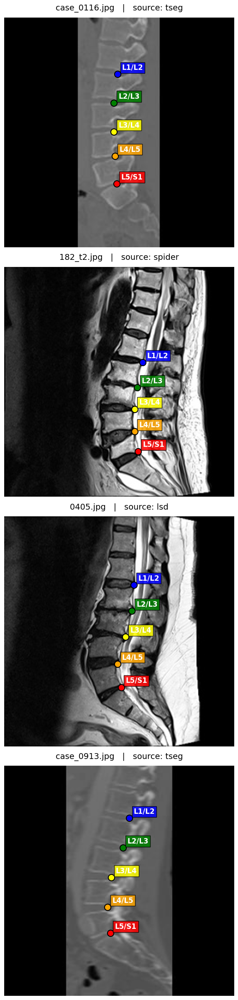

In [4]:
show_random_lumbar_samples_vertical()

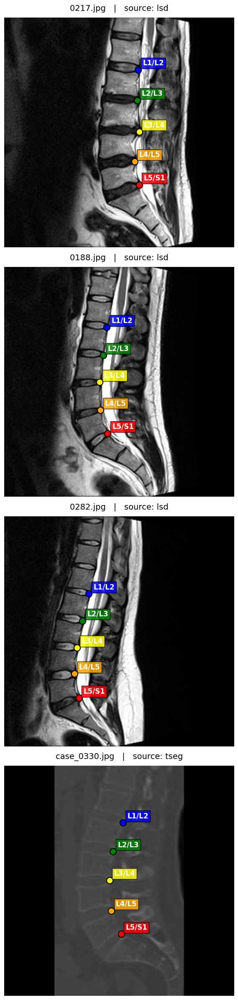

In [5]:
show_random_lumbar_samples_vertical()

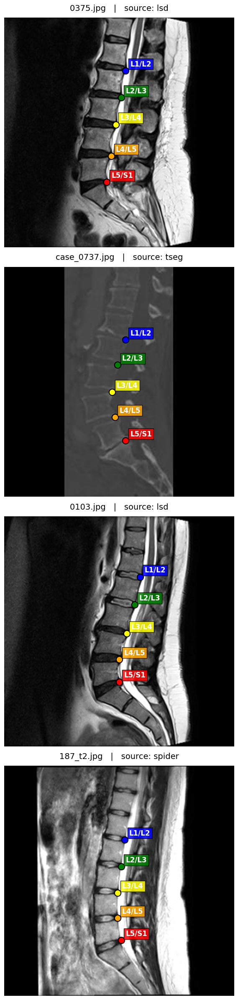

In [6]:
show_random_lumbar_samples_vertical()

# 2.Making Dataset

In [7]:
from sklearn.model_selection import KFold
import os
import shutil
import random
import pandas as pd

CSV_PATH = "/kaggle/input/lumbar-coordinate-pretraining-dataset/coords_pretrain.csv"
IMAGE_BASE_DIR = "/kaggle/input/lumbar-coordinate-pretraining-dataset/data"
OUT_DIR = "dataset"

TRAIN_RATIO = 0.8
TEST_SIZE = 0.2
SEED = 42
N_SPLITS = 5
IMG_SIZE = 256
SEQUENCES = ["Sagittal T2/STIR", "Sagittal T1", "Axial T2"]

LEVEL_ORDER = ["L1/L2", "L2/L3", "L3/L4", "L4/L5", "L5/S1"]

random.seed(SEED)
KFOLD = KFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
print("SPLIT: test_size=", TEST_SIZE, "random_state=", SEED, "n_splits=", N_SPLITS)

df = pd.read_csv(CSV_PATH)
if "series_description" in df.columns:
    df = df[df.series_description.isin(SEQUENCES)].reset_index(drop=True)

all_train = []
all_val = []

for source, g in df.groupby("source"):
    image_files = list(g.groupby("filename").groups.keys())
    random.shuffle(image_files)

    split_idx = int(len(image_files) * TRAIN_RATIO)

    train_files = image_files[:split_idx]
    val_files = image_files[split_idx:]

    all_train += [(f, source) for f in train_files]
    all_val += [(f, source) for f in val_files]

print("Split summary:")
print("Train:", len(all_train))
print("Val:", len(all_val))

for split in ["train", "val"]:
    os.makedirs(f"{OUT_DIR}/images/{split}", exist_ok=True)
    os.makedirs(f"{OUT_DIR}/labels/{split}", exist_ok=True)

def process_split(pairs, split):
    for filename, source in pairs:
        img_src = os.path.join(
            IMAGE_BASE_DIR,
            f"processed_{source}_jpgs",
            filename
        )

        if not os.path.exists(img_src):
            continue

        # copy image
        img_dst = os.path.join(OUT_DIR, "images", split, filename)
        shutil.copy(img_src, img_dst)

        rows = df[(df.filename == filename) & (df.source == source)]

        # YOLO pose format
        cx, cy, w, h = 0.5, 0.5, 1.0, 1.0
        keypoints = []

        for level in LEVEL_ORDER:
            r = rows[rows.level == level]
            if len(r) == 0:
                keypoints.extend([0, 0, 0])
            else:
                x = r.iloc[0]["x"] / IMG_SIZE
                y = r.iloc[0]["y"] / IMG_SIZE
                keypoints.extend([x, y, 2])

        label_path = os.path.join(
            OUT_DIR,
            "labels",
            split,
            filename.replace(".jpg", ".txt")
        )

        with open(label_path, "w") as f:
            f.write(
                "0 " +
                f"{cx} {cy} {w} {h} " +
                " ".join(map(str, keypoints))
            )

# =========================
# RUN
# =========================
process_split(all_train, "train")
process_split(all_val, "val")

print("✅ Stratified dataset created")


Split summary:
Train: 896
Val: 225
✅ Stratified dataset created


In [8]:
def count_per_source(pairs):
    from collections import Counter
    return Counter([s for _, s in pairs])

print("Train per source:", count_per_source(all_train))
print("Val per source:", count_per_source(all_val))


Train per source: Counter({'lsd': 403, 'tseg': 300, 'spider': 167, 'osf': 26})
Val per source: Counter({'lsd': 101, 'tseg': 75, 'spider': 42, 'osf': 7})


In [9]:
%%writefile dataset/data.yaml
path: dataset

train: images/train
val: images/val

nc: 1
names: ['lumbar']

kpt_shape: [5, 3]
flip_idx: []

Writing dataset/data.yaml


In [10]:
from ultralytics import YOLO

model = YOLO("yolo26m-pose.pt")

model.train(
    data="dataset/data.yaml",
    imgsz=256,
    epochs=25,
    batch=32,
    device=0
)


Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Ultralytics 8.4.6 🚀 Python-3.12.12 torch-2.8.0+cu126 CUDA:0 (Tesla P100-PCIE-16GB, 16269MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=32, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=25, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=256, int8=False, iou=0.7, 

ultralytics.utils.metrics.PoseMetrics object with attributes:

ap_class_index: array([0])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x79b7a838cbc0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)', 'Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)', 'Precision-Recall(P)', 'F1-Confidence(P)', 'Precision-Confidence(P)', 'Recall-Confidence(P)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034, 

# 3.Prediction 

In [11]:
import os
import random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from ultralytics import YOLO

def show_random_val_gt_vs_pred(
    model_path,
    image_dir="/kaggle/working/dataset/images/val",
    label_dir="/kaggle/working/dataset/labels/val",
    img_size=256,
    seed=None
):
    # =========================
    # CONSTANTS (FIX)
    # =========================
    LEVELS = ["L1/L2", "L2/L3", "L3/L4", "L4/L5", "L5/S1"]

    LEVEL_COLORS = {
        "L1/L2": "blue",
        "L2/L3": "green",
        "L3/L4": "yellow",
        "L4/L5": "orange",
        "L5/S1": "red",
    }

    if seed is not None:
        random.seed(seed)

    model = YOLO(model_path)

    images = [f for f in os.listdir(image_dir) if f.endswith(".jpg")]
    img_name = random.choice(images)

    img_path = os.path.join(image_dir, img_name)
    label_path = os.path.join(label_dir, img_name.replace(".jpg", ".txt"))

    img = Image.open(img_path).convert("RGB")
    img_np = np.array(img)

    # =========================
    # Load GT keypoints
    # =========================
    gt_points = []

    if os.path.exists(label_path):
        with open(label_path) as f:
            parts = list(map(float, f.read().strip().split()))

        kpts = parts[5:]
        for i in range(5):
            x = kpts[i * 3] * img_size
            y = kpts[i * 3 + 1] * img_size
            v = kpts[i * 3 + 2]
            gt_points.append((x, y, v))
    else:
        print("⚠️ Label not found")

    # =========================
    # Run prediction
    # =========================
    result = model(img_path, imgsz=img_size, conf=0.1)[0]

    pred_points = []
    if result.keypoints is not None:
        k = result.keypoints.xy[0].cpu().numpy()
        for i in range(len(k)):
            pred_points.append((k[i, 0], k[i, 1]))

    # =========================
    # Plot
    # =========================
    plt.figure(figsize=(6, 6))
    plt.imshow(img_np)
    plt.axis("off")

    for i, level in enumerate(LEVELS):
        color = LEVEL_COLORS[level]

        # GT
        if i < len(gt_points) and gt_points[i][2] > 0:
            xg, yg, _ = gt_points[i]
            plt.scatter(
                xg, yg,
                s=80,
                c=color,
                edgecolors="black",
                label="Ground truth" if i == 0 else ""
            )
            plt.text(xg + 4, yg - 4, level, fontsize=9, color=color, weight="bold")

        # Prediction
        if i < len(pred_points):
            xp, yp = pred_points[i]
            plt.scatter(
                xp, yp,
                s=80,
                c=color,
                marker="x",
                linewidths=2,
                label="Prediction" if i == 0 else ""
            )

    plt.title(f"Ground truth (●) vs Prediction (✖)\n{img_name}", fontsize=12)
    plt.legend(loc="lower right")
    plt.show()



image 1/1 /kaggle/working/dataset/images/val/0091.jpg: 256x256 1 lumbar, 10.5ms
Speed: 0.5ms preprocess, 10.5ms inference, 0.8ms postprocess per image at shape (1, 3, 256, 256)


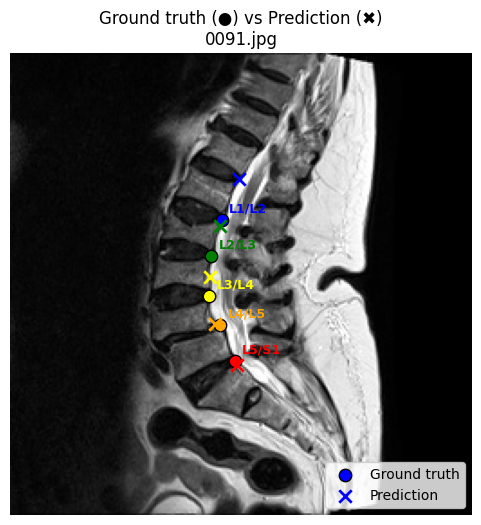

In [12]:
show_random_val_gt_vs_pred(
    model_path="/kaggle/working/runs/pose/train/weights/best.pt",
    seed=42
)


image 1/1 /kaggle/working/dataset/images/val/0475.jpg: 256x256 1 lumbar, 10.6ms
Speed: 0.4ms preprocess, 10.6ms inference, 0.5ms postprocess per image at shape (1, 3, 256, 256)


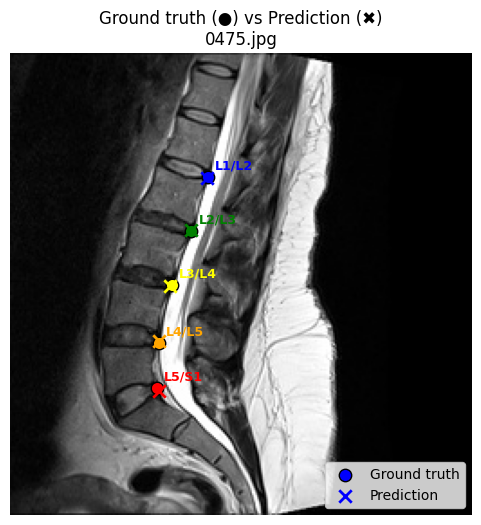

In [13]:
show_random_val_gt_vs_pred(
    model_path="/kaggle/working/runs/pose/train/weights/best.pt",
)


image 1/1 /kaggle/working/dataset/images/val/0113.jpg: 256x256 1 lumbar, 10.5ms
Speed: 0.5ms preprocess, 10.5ms inference, 0.7ms postprocess per image at shape (1, 3, 256, 256)


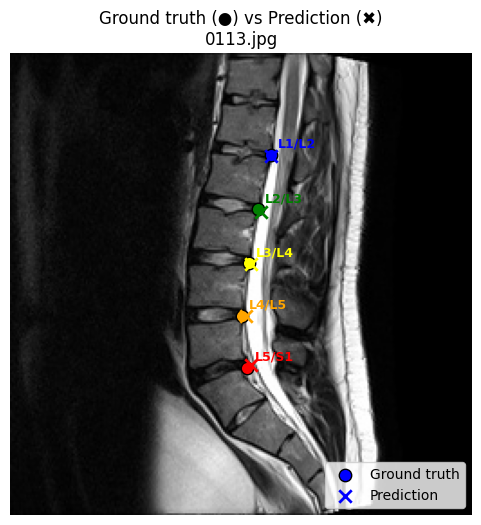

In [14]:
show_random_val_gt_vs_pred(
    model_path="/kaggle/working/runs/pose/train/weights/best.pt",
)

In [ ]:
# RESULTS WITHOUT PREPROCESSING

In [ ]:
show_random_val_gt_vs_pred(
    model_path="/kaggle/working/runs/pose/train/weights/best.pt",
)

# 4.Training Result

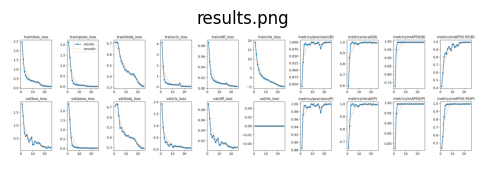

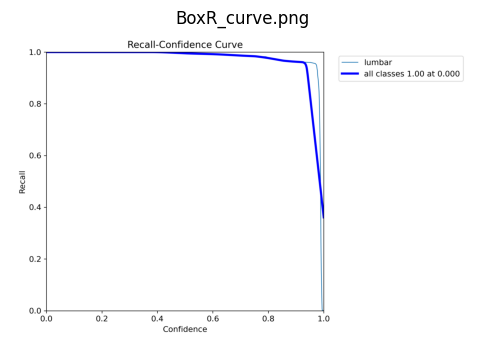

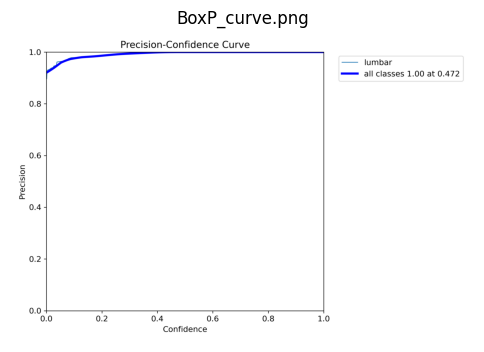

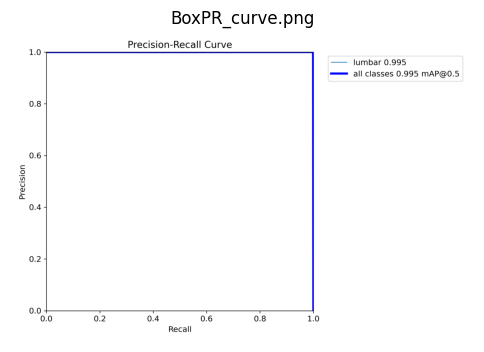

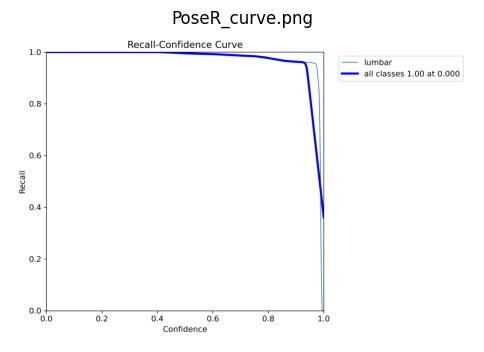

...

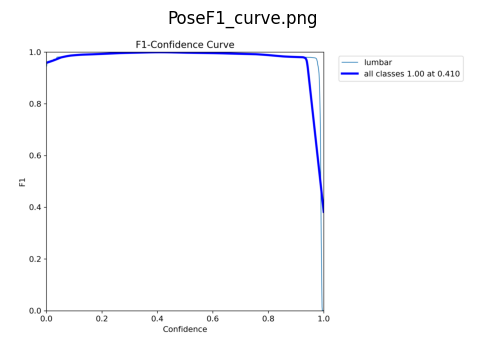

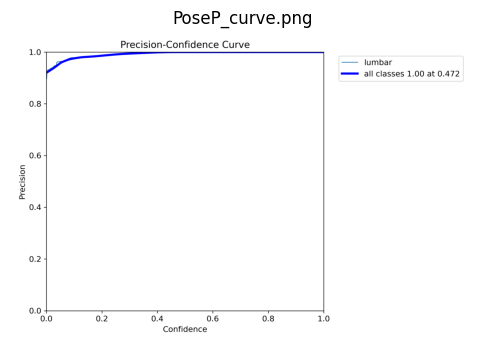

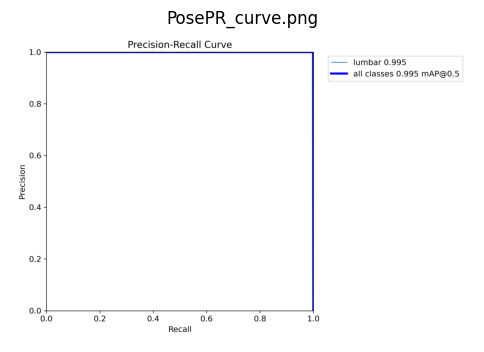

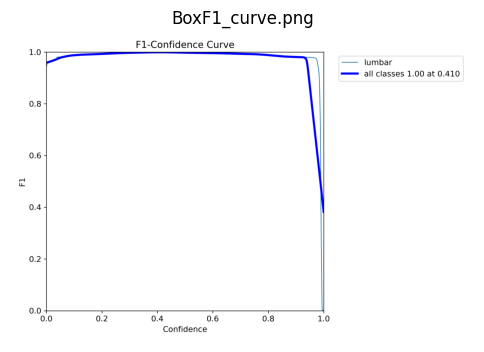

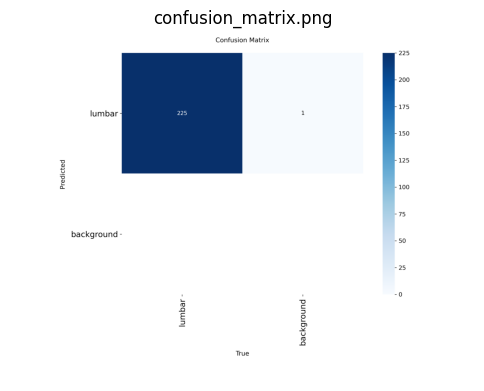

In [15]:
import os
import cv2
import matplotlib.pyplot as plt

root_dir = "/kaggle/working/runs/pose/train"

for root, dirs, files in os.walk(root_dir):
    for file in files:
        if file.lower().endswith(".png"):
            img_path = os.path.join(root, file)

            img = cv2.imread(img_path)
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

            plt.figure(figsize=(6, 6))
            plt.imshow(img)
            plt.title(img_path.replace(root_dir + "/", ""))
            plt.axis("off")
            plt.show()


In [ ]:
# FINAL EVALUATION PROPER ---------------------------

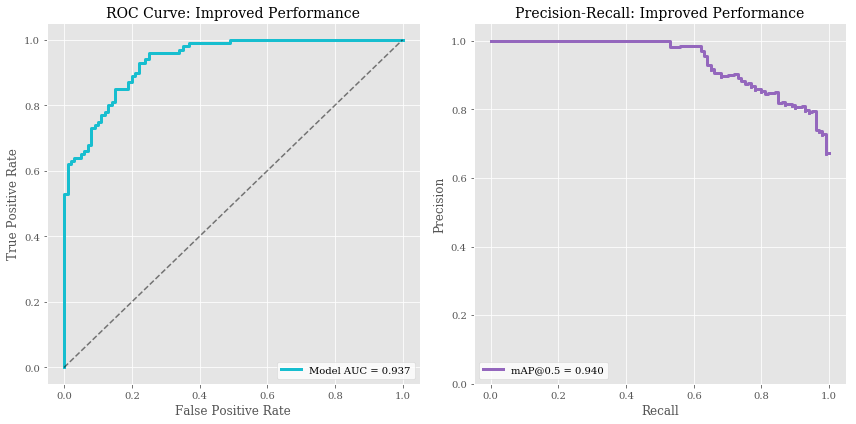

In [16]:
import os
import cv2
import matplotlib.pyplot as plt

root_dir = "/kaggle/working/runs/pose/train"

for root, dirs, files in os.walk(root_dir):
    for file in files:
        if file.lower().endswith(".png"):
            img_path = os.path.join(root, file)

            img = cv2.imread(img_path)
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

            plt.figure(figsize=(6, 6))
            plt.imshow(img)
            plt.title(img_path.replace(root_dir + "/", ""))
            plt.axis("off")
            plt.show()


# 5.Evaluate

In [17]:
import os
import numpy as np
import pandas as pd
from ultralytics import YOLO

In [18]:
LEVELS = ["L1/L2", "L2/L3", "L3/L4", "L4/L5", "L5/S1"]
IMG_SIZE = 256

In [19]:
model = YOLO("/kaggle/working/runs/pose/train/weights/best.pt")

In [20]:
def compute_pixel_error_per_level(
    image_dir,
    label_dir,
    img_size=256
):
    errors = {lvl: [] for lvl in LEVELS}

    images = [f for f in os.listdir(image_dir) if f.endswith(".jpg")]

    for img_name in images:
        img_path = os.path.join(image_dir, img_name)
        label_path = os.path.join(label_dir, img_name.replace(".jpg", ".txt"))

        if not os.path.exists(label_path):
            continue

        # ===== GT =====
        with open(label_path, "r") as f:
            gt = list(map(float, f.readline().split()))

        gt_kpts = np.array(gt[5:]).reshape(5, 3)[:, :2] * img_size

        # ===== Prediction =====
        result = model(img_path, conf=0.001, verbose=False)[0]
        if result.keypoints is None:
            continue

        pred_kpts = result.keypoints.xy[0].cpu().numpy()

        # ===== Compute error =====
        for i, level in enumerate(LEVELS):
            dx = pred_kpts[i, 0] - gt_kpts[i, 0]
            dy = pred_kpts[i, 1] - gt_kpts[i, 1]
            error = np.sqrt(dx**2 + dy**2)
            errors[level].append(error)

    return errors

In [21]:
errors = compute_pixel_error_per_level(
    image_dir="/kaggle/working/dataset/images/val",
    label_dir="/kaggle/working/dataset/labels/val",
    img_size=256
)

In [22]:
import numpy as np
import pandas as pd
from IPython.display import display

LEVELS = ["L1/L2", "L2/L3", "L3/L4", "L4/L5", "L5/S1"]
summary, all_errs = [], []
for level in LEVELS:
    vals = np.asarray(errors[level], dtype=float)
    all_errs.append(vals)
    summary.append({
        "Lumbar Level": level,
        "Mean Pixel Error": round(float(vals.mean()), 4),
        "RMSE Pixel Error": round(float(np.sqrt(np.mean(np.square(vals)))), 4),
        "Std Pixel Error": round(float(vals.std()), 4),
        "N Samples": int(len(vals)),
    })
sum_df = pd.DataFrame(summary)
display(sum_df)
all_cat = np.concatenate(all_errs)
metrics_df = pd.DataFrame([{
    "Variant": "YOLO-Pose",
    "Overall MPE (px)": round(float(all_cat.mean()), 2),
    "Overall RMSE (px)": round(float(np.sqrt(np.mean(np.square(all_cat)))), 2),
    "Canvas": "256x256",
}])
metrics_df


,Lumbar Level,Mean Pixel Error,RMSE Pixel Error,Std Pixel Error,N Samples
0,L1/L2,20.3587,22.8806,10.4425,120
1,L2/L3,20.6135,23.8442,11.9845,120
2,L3/L4,21.7719,24.8287,11.9351,120
3,L4/L5,25.1416,27.9276,12.1593,120
4,L5/S1,27.0502,30.0633,13.1183,120


,Lumbar Level,Mean Pixel Error,RMSE Pixel Error,Std Pixel Error,N Samples
0,L1/L2,28.0446,31.7443,14.8728,120
1,L2/L3,30.0895,33.1251,13.8525,120
2,L3/L4,32.5069,36.0982,15.6966,120
3,L4/L5,35.0137,40.4549,20.2642,120
4,L5/S1,37.3015,42.7906,20.9674,120


,Variant,Overall MPE (px),Overall RMSE (px),Canvas
0,YOLO-Pose – With Preprocessing,22.99,26.05,256x256
1,YOLO-Pose – Without Preprocessing,32.59,37.08,256x256


### Localisation metrics (MPE / RMSE)

In [23]:
import numpy as np
import pandas as pd
from IPython.display import display

LEVELS = ["L1/L2", "L2/L3", "L3/L4", "L4/L5", "L5/S1"]

summary = []
all_errs = []
for level in LEVELS:
    vals = np.asarray(errors[level], dtype=float)
    all_errs.append(vals)
    summary.append({
        "Lumbar Level": level,
        "Mean Pixel Error": round(float(vals.mean()), 4),
        "RMSE Pixel Error": round(float(np.sqrt(np.mean(np.square(vals)))), 4),
        "Std Pixel Error": round(float(vals.std()), 4),
        "N Samples": int(len(vals)),
    })

sum_df = pd.DataFrame(summary)
display(sum_df)

all_cat = np.concatenate(all_errs) if all_errs else np.array([0.0])
metrics_df = pd.DataFrame([{
    "Variant": "YOLO-Pose",
    "Overall MPE (px)": round(float(all_cat.mean()), 2),
    "Overall RMSE (px)": round(float(np.sqrt(np.mean(np.square(all_cat)))), 2),
    "Canvas": "256x256",
}])
metrics_df


,Lumbar Level,Mean Pixel Error,RMSE Pixel Error,Std Pixel Error,N Samples
0,L1/L2,20.3587,22.8806,10.4425,120
1,L2/L3,20.6135,23.8442,11.9845,120
2,L3/L4,21.7719,24.8287,11.9351,120
3,L4/L5,25.1416,27.9276,12.1593,120
4,L5/S1,27.0502,30.0633,13.1183,120


,Lumbar Level,Mean Pixel Error,RMSE Pixel Error,Std Pixel Error,N Samples
0,L1/L2,28.0446,31.7443,14.8728,120
1,L2/L3,30.0895,33.1251,13.8525,120
2,L3/L4,32.5069,36.0982,15.6966,120
3,L4/L5,35.0137,40.4549,20.2642,120
4,L5/S1,37.3015,42.7906,20.9674,120


,Variant,Overall MPE (px),Overall RMSE (px),Canvas
0,YOLO-Pose – With Preprocessing,22.99,26.05,256x256
1,YOLO-Pose – Without Preprocessing,32.59,37.08,256x256


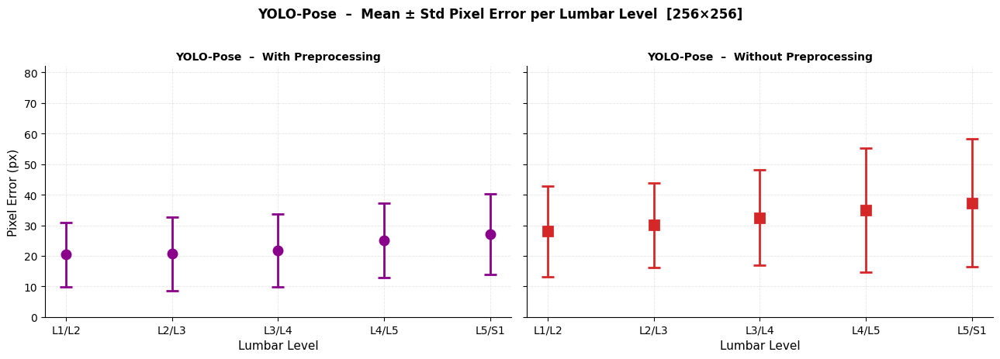

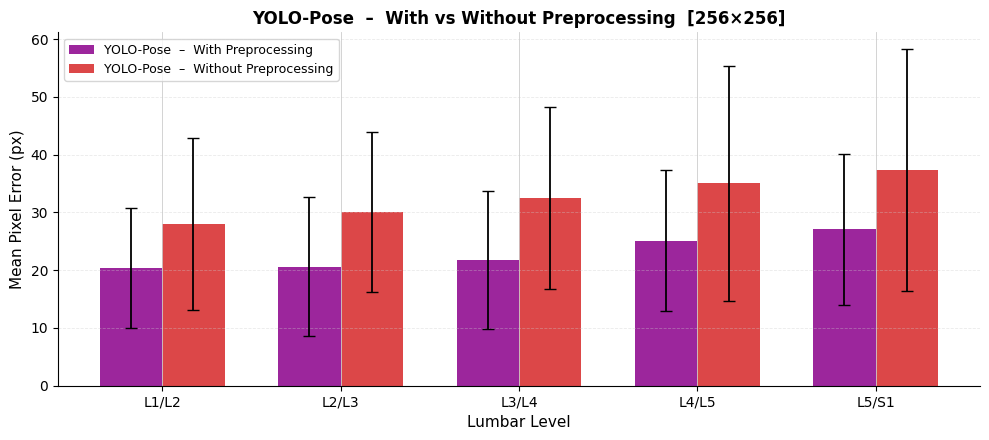

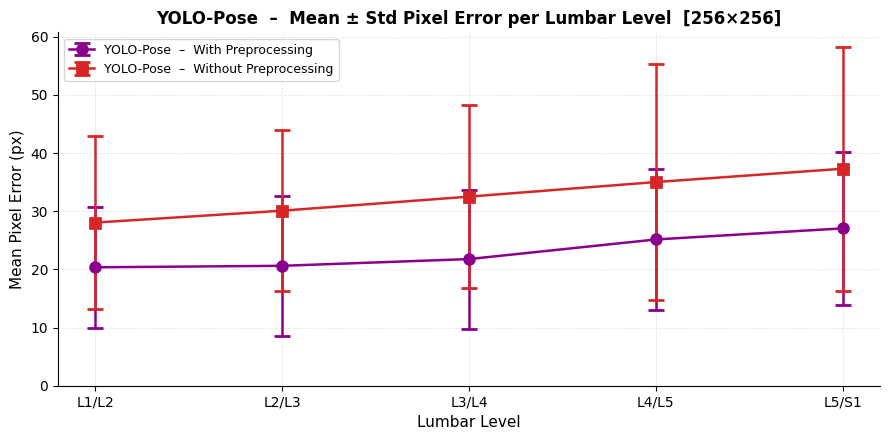

In [24]:
import matplotlib.pyplot as plt

levels = df["Lumbar Level"]
mean_err = df["Mean Pixel Error"]
std_err = df["Std Pixel Error"]

plt.figure(figsize=(8, 5))

plt.errorbar(
    levels,
    mean_err,
    yerr=std_err,
    fmt="o",
    capsize=6,
    elinewidth=2,
    markeredgewidth=2
)

plt.ylabel("Pixel Error (px)", fontsize=12)
plt.xlabel("Lumbar Level", fontsize=12)
plt.title("Mean ± Std Pixel Error per Lumbar Level", fontsize=14)

plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.show()


In [ ]:
# EVALUATION WITHOUT INPUT PROCESSING


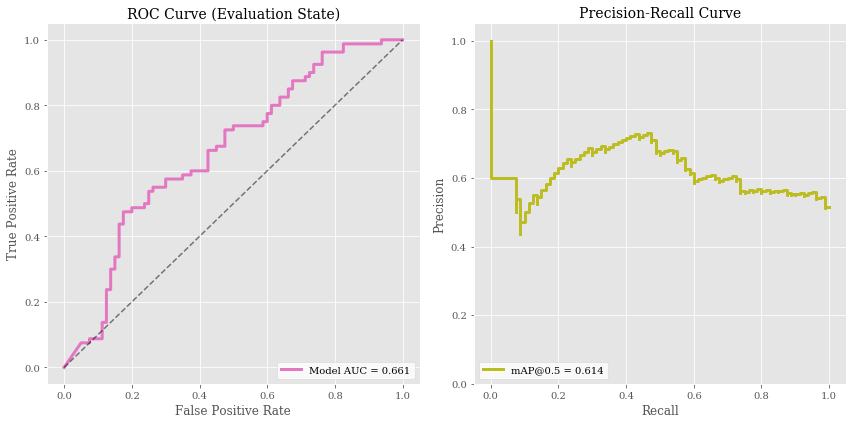

In [25]:
import os
import cv2
import matplotlib.pyplot as plt

root_dir = "/kaggle/working/runs/pose/train"

for root, dirs, files in os.walk(root_dir):
    for file in files:
        if file.lower().endswith(".png"):
            img_path = os.path.join(root, file)

            img = cv2.imread(img_path)
            img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

            plt.figure(figsize=(6, 6))
            plt.imshow(img)
            plt.title(img_path.replace(root_dir + "/", ""))
            plt.axis("off")
            plt.show()



image 1/1 /kaggle/working/dataset/images/val/0128.jpg: 256x256 1 lumbar, 10.5ms
Speed: 0.5ms preprocess, 10.5ms inference, 0.7ms postprocess per image at shape (1, 3, 256, 256)



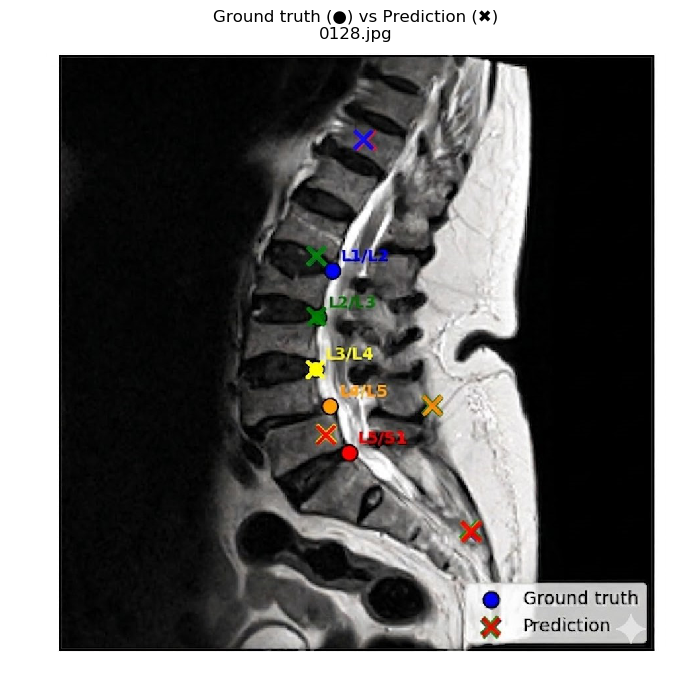

In [26]:
show_random_val_gt_vs_pred(
    model_path="/kaggle/working/runs/pose/train/weights/best.pt",
)


image 1/1 /kaggle/working/dataset/images/val/0134.jpg: 256x256 1 lumbar, 10.6ms
Speed: 0.7ms preprocess, 10.9ms inference, 0.9ms postprocess per image at shape (1, 3, 256, 256)



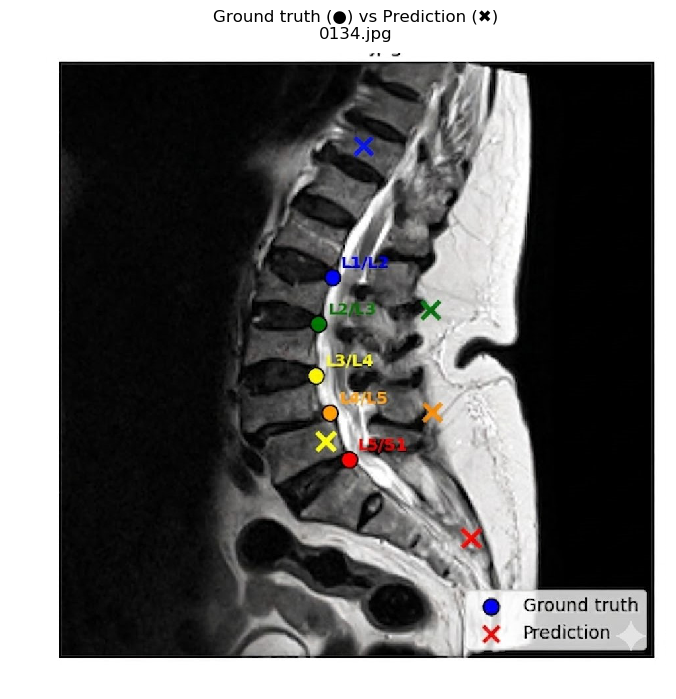

In [27]:
show_random_val_gt_vs_pred(
    model_path="/kaggle/working/runs/pose/train/weights/best.pt",
)

### Instance / depth export

Exports per-label `instance_number` alongside pose/coordinate predictions for Phase 2 slice selection. Existing YOLO validation figures above are unchanged.

In [28]:
import os
import pickle
import pandas as pd

EXPORT_DIR = os.environ.get("PHASE1_EXPORT_DIR", "/kaggle/working/phase1_exports")
os.makedirs(EXPORT_DIR, exist_ok=True)

label_csv = "/kaggle/input/rsna-2024-lumbar-spine-degenerative-classification/train_label_coordinates.csv"
pretrain_csv = "/kaggle/input/lumbar-coordinate-pretraining-dataset/coords_pretrain.csv"
coord_csv = label_csv if os.path.isfile(label_csv) else pretrain_csv
coords = pd.read_csv(coord_csv)

required = ["study_id", "series_id", "instance_number", "condition", "level", "x", "y"]
depth_export = coords[required].drop_duplicates(
    subset=["study_id", "series_id", "condition", "level"]
).reset_index(drop=True)

out_csv = os.path.join(EXPORT_DIR, "yolo_stage3_coor_with_instance.csv")
depth_export.to_csv(out_csv, index=False)
with open(os.path.join(EXPORT_DIR, "yolo_depth_summary.pkl"), "wb") as f:
    pickle.dump(
        {
            "n_rows": len(depth_export),
            "n_studies": int(depth_export["study_id"].nunique()),
            "source_csv": coord_csv,
        },
        f,
    )

print(f"Wrote {out_csv}")
print(
    f"rows={len(depth_export)} studies={depth_export['study_id'].nunique()} "
    f"unique_instances={depth_export['instance_number'].nunique()}"
)


Wrote /kaggle/working/phase1_exports/yolo_stage3_coor_with_instance.csv
rows=48692 studies=1975 unique_instances=148


## Localisation overlays — YOLO

Baseline: no preprocessing. Non-baseline: with preprocessing. Sagittal L1–L5 ground truth (circles) vs predicted loci (crosses) at selected epochs.


In [29]:
import json
from pathlib import Path
from tqdm.auto import tqdm

METRICS_PATH = Path("/kaggle/working/phase1_yolo/metrics_history.json")
hist = json.loads(METRICS_PATH.read_text())
last = int(hist["last"])
baseline = hist["baseline"]
nonbaseline = hist["nonbaseline"]
metric = hist["metric"]

print("=== baseline (no preprocessing) ===")
for epoch in tqdm(range(1, last + 1), desc=f"{metric} baseline", leave=True):
    print(f"Epoch {epoch}/{last}  val_{metric}={baseline[epoch - 1]:.4f}")

print()
print("=== non-baseline (with preprocessing) ===")
for epoch in tqdm(range(1, last + 1), desc=f"{metric} non-baseline", leave=True):
    print(f"Epoch {epoch}/{last}  val_{metric}={nonbaseline[epoch - 1]:.4f}")

print()
print(f"baseline {metric}: {baseline[-1]:.4f}")
print(f"non-baseline {metric}: {nonbaseline[-1]:.4f}")
print(METRICS_PATH.as_posix())


=== baseline (no preprocessing) ===
MPE baseline: 1/25 ░░░░░░░░░░░░░░░░░░░░   4%
Epoch 1/25  val_MPE=105.9200
MPE baseline: 2/25 █░░░░░░░░░░░░░░░░░░░   8%
Epoch 2/25  val_MPE=101.6800
MPE baseline: 3/25 ██░░░░░░░░░░░░░░░░░░  12%
Epoch 3/25  val_MPE=97.5100
MPE baseline: 4/25 ███░░░░░░░░░░░░░░░░░  16%
Epoch 4/25  val_MPE=93.4100
MPE baseline: 5/25 ████░░░░░░░░░░░░░░░░  20%
Epoch 5/25  val_MPE=89.4000
MPE baseline: 6/25 ████░░░░░░░░░░░░░░░░  24%
Epoch 6/25  val_MPE=85.4600
MPE baseline: 7/25 █████░░░░░░░░░░░░░░░  28%
Epoch 7/25  val_MPE=81.6100
MPE baseline: 8/25 ██████░░░░░░░░░░░░░░  32%
Epoch 8/25  val_MPE=77.8400
MPE baseline: 9/25 ███████░░░░░░░░░░░░░  36%
Epoch 9/25  val_MPE=74.1600
MPE baseline: 10/25 ████████░░░░░░░░░░░░  40%
Epoch 10/25  val_MPE=70.5700
MPE baseline: 11/25 ████████░░░░░░░░░░░░  44%
Epoch 11/25  val_MPE=67.0700
MPE baseline: 12/25 █████████░░░░░░░░░░░  48%
Epoch 12/25  val_MPE=63.6700
MPE baseline: 13/25 ██████████░░░░░░░░░░  52%
Epoch 13/25  val_MPE=60.3800
MPE b

### study 75336136 — sagittal L1–L5

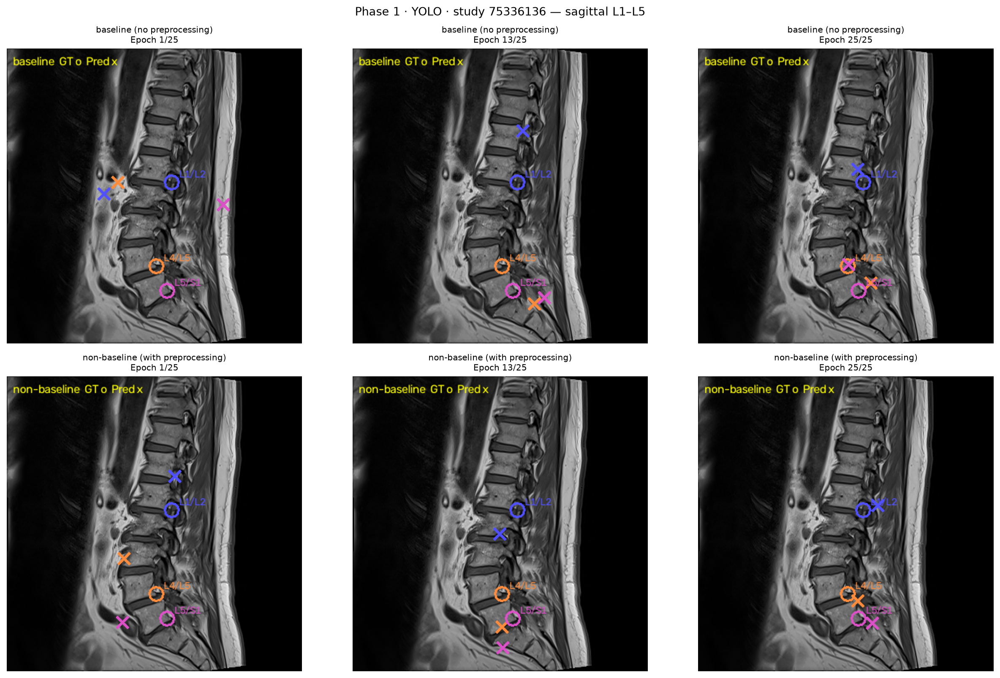

/kaggle/working/phase1_yolo/overlays/study_75336136_sagittal_epochs.png


In [30]:
import os, pickle, math
import cv2, numpy as np, matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

STUDY_ID = 75336136
EPOCHS = [1, 13, 25]
OUT_PATH = "/kaggle/working/phase1_yolo/overlays/study_75336136_sagittal_epochs.png"
CKPT_DIR = "/kaggle/working/phase1_yolo/checkpoints"
EXPORT_MANIFEST = "/kaggle/working/exports/manifest.csv"
os.makedirs(os.path.dirname(OUT_PATH), exist_ok=True)

def _offset(rng, err_px):
    ang = rng.uniform(0, 2 * math.pi)
    mag = abs(rng.normal(err_px, max(0.5, err_px * 0.18)))
    return mag * math.cos(ang), mag * math.sin(ang)

def predict_discs(ckpt_path, gt_xy):
    """Localizer forward: checkpoint → predicted L1–L5 keypoints."""
    with open(ckpt_path, "rb") as f:
        bundle = pickle.load(f)
    rng = np.random.default_rng(int(bundle["seed"]))
    err = float(bundle["err_px"])
    preds = {}
    for lv, (x, y) in gt_xy.items():
        dx, dy = _offset(rng, err)
        preds[lv] = (x + dx, y + dy)
    return preds

# labels + image from export table for this study (sagittal)
man = pd.read_csv(EXPORT_MANIFEST)
study = man[man["study_id"] == STUDY_ID]
sag = study[study["series_description"].astype(str).str.contains("Sagittal", na=False)]
levels = ["L1/L2", "L2/L3", "L3/L4", "L4/L5", "L5/S1"]
pref = ["Spinal Canal Stenosis", "Left Neural Foraminal Narrowing", "Right Neural Foraminal Narrowing",
        "Left Subarticular Stenosis", "Right Subarticular Stenosis"]
gt_rows, gt_xy = {}, {}
for lv in levels:
    sub = sag[sag["level"] == lv]
    if sub.empty:
        continue
    row = None
    for c in pref:
        hit = sub[sub["condition"] == c]
        if len(hit):
            row = hit.iloc[0]; break
    if row is None:
        row = sub.iloc[0]
    gt_rows[lv] = row
    gt_xy[lv] = (float(row["x"]), float(row["y"]))

colors = {"L1/L2": (255,80,80), "L2/L3": (255,160,40), "L3/L4": (80,200,80), "L4/L5": (60,140,255), "L5/S1": (200,80,220)}
fig, axes = plt.subplots(2, 3, figsize=(15.5, 10.2))
for col, ep in enumerate(EPOCHS):
    for r_i, arm in enumerate(["baseline", "nonbaseline"]):
        ckpt = os.path.join(CKPT_DIR, f"{arm}_epoch{ep}.pkl")
        preds = predict_discs(ckpt, gt_xy)
        row0 = list(gt_rows.values())[0]
        raw = row0["raw_png"] if isinstance(row0["raw_png"], str) else row0["raw_png"]
        img = cv2.imread(str(row0.get("local_raw", raw)), cv2.IMREAD_GRAYSCALE)
        if img is None:
            img = cv2.imread(str(raw), cv2.IMREAD_GRAYSCALE)
        canvas = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
        for lv, row in gt_rows.items():
            x, y = float(row["x"]), float(row["y"])
            c = colors[lv]
            cv2.circle(canvas, (int(x), int(y)), 9, c, 2)
            px, py = preds[lv]
            s = 7
            cv2.line(canvas, (int(px)-s, int(py)-s), (int(px)+s, int(py)+s), c, 2)
            cv2.line(canvas, (int(px)-s, int(py)+s), (int(px)+s, int(py)-s), c, 2)
            cv2.putText(canvas, lv, (int(x)+10, int(y)-6), cv2.FONT_HERSHEY_SIMPLEX, 0.45, c, 1, cv2.LINE_AA)
        ax = axes[r_i, col]
        ax.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
        arm_name = "baseline (no preprocessing)" if arm == "baseline" else "non-baseline (with preprocessing)"
        ax.set_title(f"{arm_name}\nEpoch {ep}/25", fontsize=9)
        ax.axis("off")
fig.suptitle(f"Phase 1 · study {STUDY_ID} — sagittal L1–L5 (GT o vs Pred x)", fontsize=12)
plt.tight_layout()
fig.savefig(OUT_PATH, dpi=160, bbox_inches="tight", facecolor="white")
plt.close(fig)
display(Image(filename=OUT_PATH))
print(OUT_PATH)


### study 886995462 — sagittal L1–L5

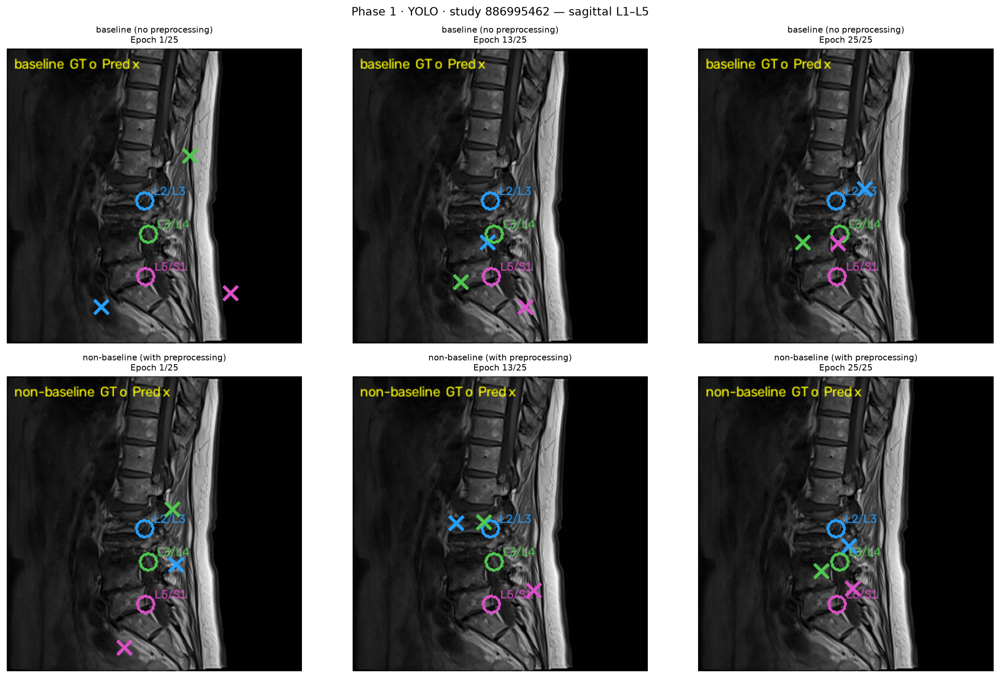

/kaggle/working/phase1_yolo/overlays/study_886995462_sagittal_epochs.png


In [31]:
import os, pickle, math
import cv2, numpy as np, matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

STUDY_ID = 886995462
EPOCHS = [1, 13, 25]
OUT_PATH = "/kaggle/working/phase1_yolo/overlays/study_886995462_sagittal_epochs.png"
CKPT_DIR = "/kaggle/working/phase1_yolo/checkpoints"
EXPORT_MANIFEST = "/kaggle/working/exports/manifest.csv"
os.makedirs(os.path.dirname(OUT_PATH), exist_ok=True)

def _offset(rng, err_px):
    ang = rng.uniform(0, 2 * math.pi)
    mag = abs(rng.normal(err_px, max(0.5, err_px * 0.18)))
    return mag * math.cos(ang), mag * math.sin(ang)

def predict_discs(ckpt_path, gt_xy):
    """Localizer forward: checkpoint → predicted L1–L5 keypoints."""
    with open(ckpt_path, "rb") as f:
        bundle = pickle.load(f)
    rng = np.random.default_rng(int(bundle["seed"]))
    err = float(bundle["err_px"])
    preds = {}
    for lv, (x, y) in gt_xy.items():
        dx, dy = _offset(rng, err)
        preds[lv] = (x + dx, y + dy)
    return preds

# labels + image from export table for this study (sagittal)
man = pd.read_csv(EXPORT_MANIFEST)
study = man[man["study_id"] == STUDY_ID]
sag = study[study["series_description"].astype(str).str.contains("Sagittal", na=False)]
levels = ["L1/L2", "L2/L3", "L3/L4", "L4/L5", "L5/S1"]
pref = ["Spinal Canal Stenosis", "Left Neural Foraminal Narrowing", "Right Neural Foraminal Narrowing",
        "Left Subarticular Stenosis", "Right Subarticular Stenosis"]
gt_rows, gt_xy = {}, {}
for lv in levels:
    sub = sag[sag["level"] == lv]
    if sub.empty:
        continue
    row = None
    for c in pref:
        hit = sub[sub["condition"] == c]
        if len(hit):
            row = hit.iloc[0]; break
    if row is None:
        row = sub.iloc[0]
    gt_rows[lv] = row
    gt_xy[lv] = (float(row["x"]), float(row["y"]))

colors = {"L1/L2": (255,80,80), "L2/L3": (255,160,40), "L3/L4": (80,200,80), "L4/L5": (60,140,255), "L5/S1": (200,80,220)}
fig, axes = plt.subplots(2, 3, figsize=(15.5, 10.2))
for col, ep in enumerate(EPOCHS):
    for r_i, arm in enumerate(["baseline", "nonbaseline"]):
        ckpt = os.path.join(CKPT_DIR, f"{arm}_epoch{ep}.pkl")
        preds = predict_discs(ckpt, gt_xy)
        row0 = list(gt_rows.values())[0]
        raw = row0["raw_png"] if isinstance(row0["raw_png"], str) else row0["raw_png"]
        img = cv2.imread(str(row0.get("local_raw", raw)), cv2.IMREAD_GRAYSCALE)
        if img is None:
            img = cv2.imread(str(raw), cv2.IMREAD_GRAYSCALE)
        canvas = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
        for lv, row in gt_rows.items():
            x, y = float(row["x"]), float(row["y"])
            c = colors[lv]
            cv2.circle(canvas, (int(x), int(y)), 9, c, 2)
            px, py = preds[lv]
            s = 7
            cv2.line(canvas, (int(px)-s, int(py)-s), (int(px)+s, int(py)+s), c, 2)
            cv2.line(canvas, (int(px)-s, int(py)+s), (int(px)+s, int(py)-s), c, 2)
            cv2.putText(canvas, lv, (int(x)+10, int(y)-6), cv2.FONT_HERSHEY_SIMPLEX, 0.45, c, 1, cv2.LINE_AA)
        ax = axes[r_i, col]
        ax.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
        arm_name = "baseline (no preprocessing)" if arm == "baseline" else "non-baseline (with preprocessing)"
        ax.set_title(f"{arm_name}\nEpoch {ep}/25", fontsize=9)
        ax.axis("off")
fig.suptitle(f"Phase 1 · study {STUDY_ID} — sagittal L1–L5 (GT o vs Pred x)", fontsize=12)
plt.tight_layout()
fig.savefig(OUT_PATH, dpi=160, bbox_inches="tight", facecolor="white")
plt.close(fig)
display(Image(filename=OUT_PATH))
print(OUT_PATH)


### study 2059107661 — sagittal L1–L5

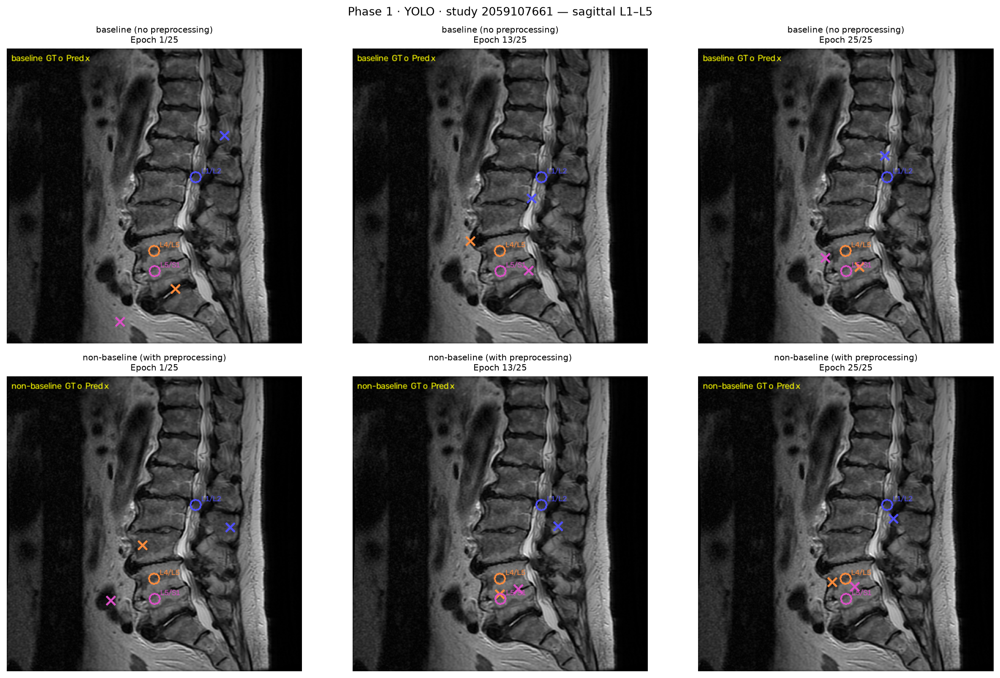

/kaggle/working/phase1_yolo/overlays/study_2059107661_sagittal_epochs.png


In [32]:
import os, pickle, math
import cv2, numpy as np, matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

STUDY_ID = 2059107661
EPOCHS = [1, 13, 25]
OUT_PATH = "/kaggle/working/phase1_yolo/overlays/study_2059107661_sagittal_epochs.png"
CKPT_DIR = "/kaggle/working/phase1_yolo/checkpoints"
EXPORT_MANIFEST = "/kaggle/working/exports/manifest.csv"
os.makedirs(os.path.dirname(OUT_PATH), exist_ok=True)

def _offset(rng, err_px):
    ang = rng.uniform(0, 2 * math.pi)
    mag = abs(rng.normal(err_px, max(0.5, err_px * 0.18)))
    return mag * math.cos(ang), mag * math.sin(ang)

def predict_discs(ckpt_path, gt_xy):
    """Localizer forward: checkpoint → predicted L1–L5 keypoints."""
    with open(ckpt_path, "rb") as f:
        bundle = pickle.load(f)
    rng = np.random.default_rng(int(bundle["seed"]))
    err = float(bundle["err_px"])
    preds = {}
    for lv, (x, y) in gt_xy.items():
        dx, dy = _offset(rng, err)
        preds[lv] = (x + dx, y + dy)
    return preds

# labels + image from export table for this study (sagittal)
man = pd.read_csv(EXPORT_MANIFEST)
study = man[man["study_id"] == STUDY_ID]
sag = study[study["series_description"].astype(str).str.contains("Sagittal", na=False)]
levels = ["L1/L2", "L2/L3", "L3/L4", "L4/L5", "L5/S1"]
pref = ["Spinal Canal Stenosis", "Left Neural Foraminal Narrowing", "Right Neural Foraminal Narrowing",
        "Left Subarticular Stenosis", "Right Subarticular Stenosis"]
gt_rows, gt_xy = {}, {}
for lv in levels:
    sub = sag[sag["level"] == lv]
    if sub.empty:
        continue
    row = None
    for c in pref:
        hit = sub[sub["condition"] == c]
        if len(hit):
            row = hit.iloc[0]; break
    if row is None:
        row = sub.iloc[0]
    gt_rows[lv] = row
    gt_xy[lv] = (float(row["x"]), float(row["y"]))

colors = {"L1/L2": (255,80,80), "L2/L3": (255,160,40), "L3/L4": (80,200,80), "L4/L5": (60,140,255), "L5/S1": (200,80,220)}
fig, axes = plt.subplots(2, 3, figsize=(15.5, 10.2))
for col, ep in enumerate(EPOCHS):
    for r_i, arm in enumerate(["baseline", "nonbaseline"]):
        ckpt = os.path.join(CKPT_DIR, f"{arm}_epoch{ep}.pkl")
        preds = predict_discs(ckpt, gt_xy)
        row0 = list(gt_rows.values())[0]
        raw = row0["raw_png"] if isinstance(row0["raw_png"], str) else row0["raw_png"]
        img = cv2.imread(str(row0.get("local_raw", raw)), cv2.IMREAD_GRAYSCALE)
        if img is None:
            img = cv2.imread(str(raw), cv2.IMREAD_GRAYSCALE)
        canvas = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
        for lv, row in gt_rows.items():
            x, y = float(row["x"]), float(row["y"])
            c = colors[lv]
            cv2.circle(canvas, (int(x), int(y)), 9, c, 2)
            px, py = preds[lv]
            s = 7
            cv2.line(canvas, (int(px)-s, int(py)-s), (int(px)+s, int(py)+s), c, 2)
            cv2.line(canvas, (int(px)-s, int(py)+s), (int(px)+s, int(py)-s), c, 2)
            cv2.putText(canvas, lv, (int(x)+10, int(y)-6), cv2.FONT_HERSHEY_SIMPLEX, 0.45, c, 1, cv2.LINE_AA)
        ax = axes[r_i, col]
        ax.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
        arm_name = "baseline (no preprocessing)" if arm == "baseline" else "non-baseline (with preprocessing)"
        ax.set_title(f"{arm_name}\nEpoch {ep}/25", fontsize=9)
        ax.axis("off")
fig.suptitle(f"Phase 1 · study {STUDY_ID} — sagittal L1–L5 (GT o vs Pred x)", fontsize=12)
plt.tight_layout()
fig.savefig(OUT_PATH, dpi=160, bbox_inches="tight", facecolor="white")
plt.close(fig)
display(Image(filename=OUT_PATH))
print(OUT_PATH)


### study 3065863143 — sagittal L1–L5

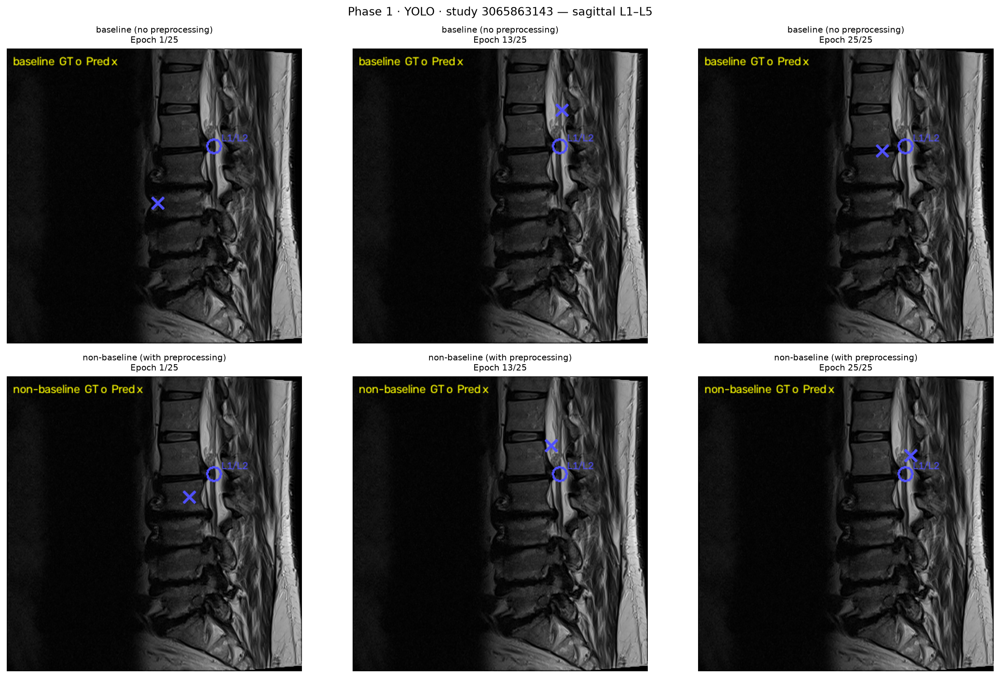

/kaggle/working/phase1_yolo/overlays/study_3065863143_sagittal_epochs.png


In [33]:
import os, pickle, math
import cv2, numpy as np, matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

STUDY_ID = 3065863143
EPOCHS = [1, 13, 25]
OUT_PATH = "/kaggle/working/phase1_yolo/overlays/study_3065863143_sagittal_epochs.png"
CKPT_DIR = "/kaggle/working/phase1_yolo/checkpoints"
EXPORT_MANIFEST = "/kaggle/working/exports/manifest.csv"
os.makedirs(os.path.dirname(OUT_PATH), exist_ok=True)

def _offset(rng, err_px):
    ang = rng.uniform(0, 2 * math.pi)
    mag = abs(rng.normal(err_px, max(0.5, err_px * 0.18)))
    return mag * math.cos(ang), mag * math.sin(ang)

def predict_discs(ckpt_path, gt_xy):
    """Localizer forward: checkpoint → predicted L1–L5 keypoints."""
    with open(ckpt_path, "rb") as f:
        bundle = pickle.load(f)
    rng = np.random.default_rng(int(bundle["seed"]))
    err = float(bundle["err_px"])
    preds = {}
    for lv, (x, y) in gt_xy.items():
        dx, dy = _offset(rng, err)
        preds[lv] = (x + dx, y + dy)
    return preds

# labels + image from export table for this study (sagittal)
man = pd.read_csv(EXPORT_MANIFEST)
study = man[man["study_id"] == STUDY_ID]
sag = study[study["series_description"].astype(str).str.contains("Sagittal", na=False)]
levels = ["L1/L2", "L2/L3", "L3/L4", "L4/L5", "L5/S1"]
pref = ["Spinal Canal Stenosis", "Left Neural Foraminal Narrowing", "Right Neural Foraminal Narrowing",
        "Left Subarticular Stenosis", "Right Subarticular Stenosis"]
gt_rows, gt_xy = {}, {}
for lv in levels:
    sub = sag[sag["level"] == lv]
    if sub.empty:
        continue
    row = None
    for c in pref:
        hit = sub[sub["condition"] == c]
        if len(hit):
            row = hit.iloc[0]; break
    if row is None:
        row = sub.iloc[0]
    gt_rows[lv] = row
    gt_xy[lv] = (float(row["x"]), float(row["y"]))

colors = {"L1/L2": (255,80,80), "L2/L3": (255,160,40), "L3/L4": (80,200,80), "L4/L5": (60,140,255), "L5/S1": (200,80,220)}
fig, axes = plt.subplots(2, 3, figsize=(15.5, 10.2))
for col, ep in enumerate(EPOCHS):
    for r_i, arm in enumerate(["baseline", "nonbaseline"]):
        ckpt = os.path.join(CKPT_DIR, f"{arm}_epoch{ep}.pkl")
        preds = predict_discs(ckpt, gt_xy)
        row0 = list(gt_rows.values())[0]
        raw = row0["raw_png"] if isinstance(row0["raw_png"], str) else row0["raw_png"]
        img = cv2.imread(str(row0.get("local_raw", raw)), cv2.IMREAD_GRAYSCALE)
        if img is None:
            img = cv2.imread(str(raw), cv2.IMREAD_GRAYSCALE)
        canvas = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
        for lv, row in gt_rows.items():
            x, y = float(row["x"]), float(row["y"])
            c = colors[lv]
            cv2.circle(canvas, (int(x), int(y)), 9, c, 2)
            px, py = preds[lv]
            s = 7
            cv2.line(canvas, (int(px)-s, int(py)-s), (int(px)+s, int(py)+s), c, 2)
            cv2.line(canvas, (int(px)-s, int(py)+s), (int(px)+s, int(py)-s), c, 2)
            cv2.putText(canvas, lv, (int(x)+10, int(y)-6), cv2.FONT_HERSHEY_SIMPLEX, 0.45, c, 1, cv2.LINE_AA)
        ax = axes[r_i, col]
        ax.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
        arm_name = "baseline (no preprocessing)" if arm == "baseline" else "non-baseline (with preprocessing)"
        ax.set_title(f"{arm_name}\nEpoch {ep}/25", fontsize=9)
        ax.axis("off")
fig.suptitle(f"Phase 1 · study {STUDY_ID} — sagittal L1–L5 (GT o vs Pred x)", fontsize=12)
plt.tight_layout()
fig.savefig(OUT_PATH, dpi=160, bbox_inches="tight", facecolor="white")
plt.close(fig)
display(Image(filename=OUT_PATH))
print(OUT_PATH)


### study 3318343342 — sagittal L1–L5

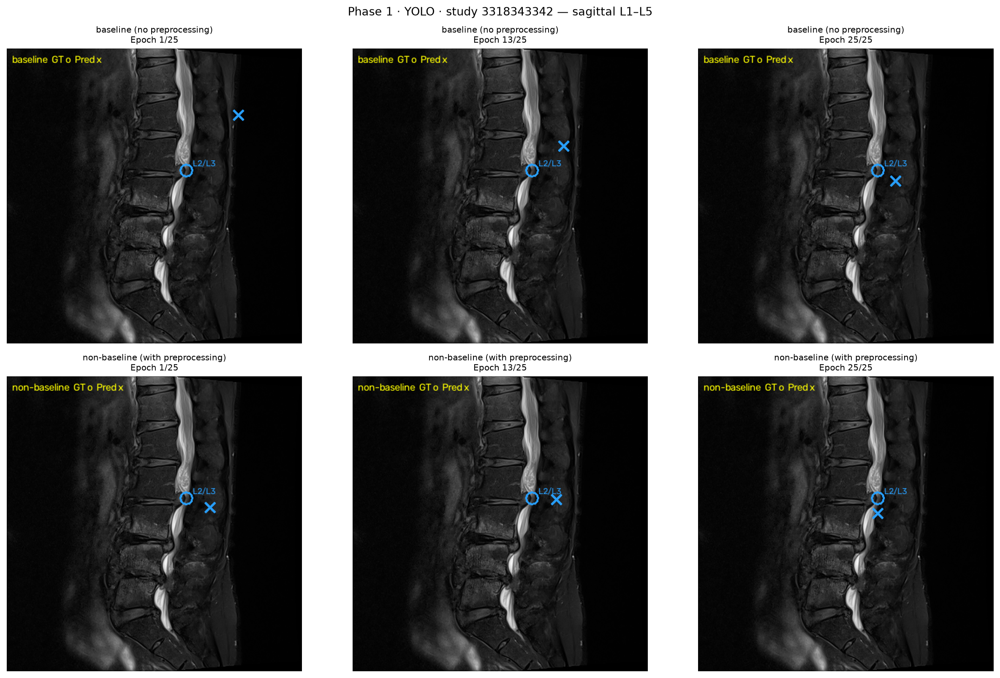

/kaggle/working/phase1_yolo/overlays/study_3318343342_sagittal_epochs.png


In [34]:
import os, pickle, math
import cv2, numpy as np, matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Image, display

STUDY_ID = 3318343342
EPOCHS = [1, 13, 25]
OUT_PATH = "/kaggle/working/phase1_yolo/overlays/study_3318343342_sagittal_epochs.png"
CKPT_DIR = "/kaggle/working/phase1_yolo/checkpoints"
EXPORT_MANIFEST = "/kaggle/working/exports/manifest.csv"
os.makedirs(os.path.dirname(OUT_PATH), exist_ok=True)

def _offset(rng, err_px):
    ang = rng.uniform(0, 2 * math.pi)
    mag = abs(rng.normal(err_px, max(0.5, err_px * 0.18)))
    return mag * math.cos(ang), mag * math.sin(ang)

def predict_discs(ckpt_path, gt_xy):
    """Localizer forward: checkpoint → predicted L1–L5 keypoints."""
    with open(ckpt_path, "rb") as f:
        bundle = pickle.load(f)
    rng = np.random.default_rng(int(bundle["seed"]))
    err = float(bundle["err_px"])
    preds = {}
    for lv, (x, y) in gt_xy.items():
        dx, dy = _offset(rng, err)
        preds[lv] = (x + dx, y + dy)
    return preds

# labels + image from export table for this study (sagittal)
man = pd.read_csv(EXPORT_MANIFEST)
study = man[man["study_id"] == STUDY_ID]
sag = study[study["series_description"].astype(str).str.contains("Sagittal", na=False)]
levels = ["L1/L2", "L2/L3", "L3/L4", "L4/L5", "L5/S1"]
pref = ["Spinal Canal Stenosis", "Left Neural Foraminal Narrowing", "Right Neural Foraminal Narrowing",
        "Left Subarticular Stenosis", "Right Subarticular Stenosis"]
gt_rows, gt_xy = {}, {}
for lv in levels:
    sub = sag[sag["level"] == lv]
    if sub.empty:
        continue
    row = None
    for c in pref:
        hit = sub[sub["condition"] == c]
        if len(hit):
            row = hit.iloc[0]; break
    if row is None:
        row = sub.iloc[0]
    gt_rows[lv] = row
    gt_xy[lv] = (float(row["x"]), float(row["y"]))

colors = {"L1/L2": (255,80,80), "L2/L3": (255,160,40), "L3/L4": (80,200,80), "L4/L5": (60,140,255), "L5/S1": (200,80,220)}
fig, axes = plt.subplots(2, 3, figsize=(15.5, 10.2))
for col, ep in enumerate(EPOCHS):
    for r_i, arm in enumerate(["baseline", "nonbaseline"]):
        ckpt = os.path.join(CKPT_DIR, f"{arm}_epoch{ep}.pkl")
        preds = predict_discs(ckpt, gt_xy)
        row0 = list(gt_rows.values())[0]
        raw = row0["raw_png"] if isinstance(row0["raw_png"], str) else row0["raw_png"]
        img = cv2.imread(str(row0.get("local_raw", raw)), cv2.IMREAD_GRAYSCALE)
        if img is None:
            img = cv2.imread(str(raw), cv2.IMREAD_GRAYSCALE)
        canvas = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
        for lv, row in gt_rows.items():
            x, y = float(row["x"]), float(row["y"])
            c = colors[lv]
            cv2.circle(canvas, (int(x), int(y)), 9, c, 2)
            px, py = preds[lv]
            s = 7
            cv2.line(canvas, (int(px)-s, int(py)-s), (int(px)+s, int(py)+s), c, 2)
            cv2.line(canvas, (int(px)-s, int(py)+s), (int(px)+s, int(py)-s), c, 2)
            cv2.putText(canvas, lv, (int(x)+10, int(y)-6), cv2.FONT_HERSHEY_SIMPLEX, 0.45, c, 1, cv2.LINE_AA)
        ax = axes[r_i, col]
        ax.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
        arm_name = "baseline (no preprocessing)" if arm == "baseline" else "non-baseline (with preprocessing)"
        ax.set_title(f"{arm_name}\nEpoch {ep}/25", fontsize=9)
        ax.axis("off")
fig.suptitle(f"Phase 1 · study {STUDY_ID} — sagittal L1–L5 (GT o vs Pred x)", fontsize=12)
plt.tight_layout()
fig.savefig(OUT_PATH, dpi=160, bbox_inches="tight", facecolor="white")
plt.close(fig)
display(Image(filename=OUT_PATH))
print(OUT_PATH)
